# Adım 3 (v2): Son CNN'in seçimi, kalibrasyon, test, uzmana yönlendirme ve Grad-CAM

Bu defter **yeni eğitim yapmaz.** Adım 2'de eğitilen modellerden ve onların birleşimlerinden konseyde kullanılacak **son CNN'i** seçer, sonra test kümesinde değerlendirir. Bu adımdan sonra CNN **dondurulur**.

**Adaylar (test kümesine bakılmadan önce sabitlendi):**
| Aday | Açıklama |
|---|---|
| cnn_b0_v3 / + TTA | Şu ana kadarki ana model |
| cnn_b3_v3 / + TTA | Daha büyük model; melanom duyarlılığı daha yüksek |
| cnn_b0_v4 / + TTA | Yeni eğitim tarifi (doğrulamada geride kaldı, ama bütün modeller raporlanır) |
| Topluluk / + TTA | B0 v3 ile B3 v3'ün logit ortalaması |

**TTA (test anında çoğaltma):** Her görüntü 8 yönde (4 döndürme × aynalama) tahmin edilip logitler ortalanır.

**Kurallar (hepsi yalnızca doğrulama kümesine göre):**
1. **Seçim:** En yüksek ayarsız dengeli doğruluk. Fark 0,01'den küçükse doğrulama kaybı (NLL) düşük olan seçilir. Adım 2'deki kuralın aynısı.
2. **Kalibrasyon:** Her aday için ayrı bir sıcaklık T bulunur.
3. **Karar kuralı (τ):** Sistemin ana kararı **klinik τ** ile verilir: nevüs duyarlılığı en az 0,80 kalacak şekilde dengeli doğruluğu en yükselten τ. Dengeli doğruluğu tek başına en yükselten τ da karşılaştırma için raporlanır.
4. Bütün ayarlar dondurulduktan sonra test kümesi açılır ve **bütün adayların** test sonuçları raporlanır. Ayrıntılı analiz (güven aralıkları, uzmana yönlendirme, Grad-CAM) seçilen aday için yapılır.

**Şeffaflık notu:** cnn_b0_v3'ün test sonucu Adım 3'ün ilk sürümünde bir kez görüldü. Bu defterin seçimi testten etkilenmez, çünkü seçim yalnızca doğrulamaya göre yapılır. Ama bu durum tezde açıkça yazılmalıdır. İlk sürümün dosyaları silinmez; bu defterin çıktıları `03v2_` ön ekiyle kaydedilir.

**Ön işleme tutarlılığı:** v3 modelleri, küçültülen görüntüleri tam sayıya keserek; v4 ise yuvarlayarak eğitildi. Her model kendi eğitildiği ön işlemeyle değerlendirilir, ve hesaplanan logitlerin Adım 2'de kaydedilenlerle aynı olduğu kontrol edilir.

**Çalışma zamanı:** GPU (T4 yeterli; A100/L4 daha hızlı). Süre yaklaşık 20-30 dakika.

## 1. Ortam ve ayarlar

In [2]:
import os, json, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy.optimize import minimize_scalar
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)

from google.colab import drive
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'

# ---- Ayarlar (test açılmadan önce sabitlendi) ----
TEMEL_MODELLER = ['cnn_b0_v3', 'cnn_b3_v3', 'cnn_b0_v4']
TOPLULUK = ['cnn_b0_v3', 'cnn_b3_v3']
NEVUS_ALT_SINIR = 0.80     # klinik τ: nevüs duyarlılığı en az bu kadar
SECIM_FARKI = 0.01         # dengeli doğrulukta bu kadarlık fark "eşit" sayılır, NLL'ye bakılır
BATCH = 32
TOHUM = 42
ON = '03v2'                # çıktı dosyalarının ön eki
rng = np.random.default_rng(TOHUM)
warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')

SINIFLAR = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
SINIF_ADI = {'akiec': 'Aktinik keratoz', 'bcc': 'Bazal hücreli karsinom', 'bkl': 'Benign keratoz',
             'df': 'Dermatofibrom', 'mel': 'Melanom', 'nv': 'Melanositik nevüs (ben)', 'vasc': 'Vasküler lezyon'}
ETIKET = [SINIF_ADI[s] for s in SINIFLAR]
MEL, NV = SINIFLAR.index('mel'), SINIFLAR.index('nv')

# Her modelin Adım 2 bilgileri: giriş boyutu, ön işleme, Grad-CAM katmanı
BILGI, MODELLER = {}, {}
for m in TEMEL_MODELLER:
    with open(f'{PROJE}/results/02_{m}_dogrulama_metrikleri.json', encoding='utf-8') as f:
        j = json.load(f)
    assert j['siniflar'] == SINIFLAR, f'{m}: sınıf sırası farklı!'
    BILGI[m] = {'img': j['img'],
                'onisleme': j.get('onisleme', 'kes_uint8'),        # v3 defterinde bu alan yoktu: kesme
                'cam_katmani': j.get('cam_katmani', 'top_activation')}
    MODELLER[m] = keras.models.load_model(f'{PROJE}/models/{m}.keras')

print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU') or 'YOK')
print(pd.DataFrame(BILGI).T.to_string())

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 232 variables whereas the saved optimizer has 236 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 370 variables whereas the saved optimizer has 374 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
           img       onisleme     cam_katmani
cnn_b0_v3  224      kes_uint8  top_activation
cnn_b3_v3  300      kes_uint8  top_activation
cnn_b0_v4  224  yuvarla_uint8  top_activation


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 231 variables whereas the saved optimizer has 235 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [3]:
ZIP = f'{PROJE}/data/skin-cancer-mnist-ham10000.zip'
if not os.path.exists('/content/ham'):
    !unzip -q -n "{ZIP}" -d /content/ham
GORUNTU_KOKU = '/content/ham'

yollar = {}
for p in glob.glob(f'{GORUNTU_KOKU}/**/*.jpg', recursive=True):
    yollar.setdefault(os.path.splitext(os.path.basename(p))[0], p)

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
meta['path'] = meta['image_id'].map(yollar)
meta['y'] = meta['dx'].map({s: i for i, s in enumerate(SINIFLAR)})
assert meta['path'].notna().all()
assert meta.groupby('lesion_id')['split'].nunique().max() == 1

egitim    = meta[meta['split'] == 'egitim'].reset_index(drop=True)
dogrulama = meta[meta['split'] == 'dogrulama'].reset_index(drop=True)
test      = meta[meta['split'] == 'test'].reset_index(drop=True)
y_dog, y_test = dogrulama['y'].values, test['y'].values

# Eğitimdeki sınıf oranları: karar kuralı (logit ayarı) bunları kullanır
oncel = np.bincount(egitim['y'], minlength=len(SINIFLAR)) / len(egitim)
LOG_ONCEL = np.log(oncel)
print('Eğitim:', len(egitim), '| Doğrulama:', len(dogrulama), '| Test:', len(test))

Eğitim: 7054 | Doğrulama: 1464 | Test: 1497


## 2. Ön işleme, TTA ve doğrulama logitleri
- `onisle`: Görüntüyü modelin giriş boyutuna küçültür, sonra modelin eğitildiği yöntemle tam sayıya çevirir (v3: kesme, v4: yuvarlama).
- `logit_hesapla`: Her görüntü için tek geçiş ve TTA (8 yön) logitlerini birlikte hesaplar.
- **Tutarlılık kontrolü:** Tek geçiş logitleri Adım 2'de kaydedilenlerle karşılaştırılır. En büyük farkın çok küçük olması (≈0,01'in altı) beklenir; bu, Drive'daki modelin ve ön işlemenin doğru olduğunu gösterir.

In [4]:
def onisle(goruntu, img, yontem):
    goruntu = tf.image.resize(goruntu, (img, img))
    if yontem == 'yuvarla_uint8':
        goruntu = tf.round(tf.clip_by_value(goruntu, 0, 255))
    return tf.cast(tf.cast(goruntu, tf.uint8), tf.float32)   # 'kes_uint8': doğrudan çevirme kesirli kısmı atar

def veri_hatti(df, m):
    img, yontem = BILGI[m]['img'], BILGI[m]['onisleme']
    def yukle(yol):
        return onisle(tf.io.decode_jpeg(tf.io.read_file(yol), channels=3), img, yontem)
    return (tf.data.Dataset.from_tensor_slices(df['path'].values)
            .map(yukle, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE))

def logit_hesapla(m, df):
    model = MODELLER[m]
    @tf.function(reduce_retracing=True)
    def tek(x):
        return tf.cast(model(x, training=False), tf.float32)
    @tf.function(reduce_retracing=True)
    def tta(x):
        gorunumler = []
        for aynala in (False, True):                 # 2 × 4 = 8 yön
            xx = tf.image.flip_left_right(x) if aynala else x
            for k in range(4):
                gorunumler.append(tf.cast(model(tf.image.rot90(xx, k), training=False), tf.float32))
        return tf.add_n(gorunumler) / 8.0
    a, b = [], []
    for x in veri_hatti(df, m):
        a.append(tek(x).numpy()); b.append(tta(x).numpy())
    return {'tek': np.concatenate(a).astype('float64'), 'tta': np.concatenate(b).astype('float64')}

LOGIT_DOG = {}
for m in TEMEL_MODELLER:
    t0 = time.time()
    LOGIT_DOG[m] = logit_hesapla(m, dogrulama)
    kayit_yolu = f'{PROJE}/models/{m}_dogrulama_logit_tek.npy'
    if not os.path.exists(kayit_yolu):
        kayit_yolu = f'{PROJE}/models/{m}_dogrulama_logit.npy'
    fark = np.abs(LOGIT_DOG[m]['tek'] - np.load(kayit_yolu)).max()
    print(f'{m}: {(time.time() - t0) / 60:.1f} dk | Adım 2 ile en büyük fark {fark:.4f} '
          f'-> {"TUTARLI" if fark < 0.05 else "DİKKAT: tutarsız, bana haber ver"}')

cnn_b0_v3: 1.2 dk | Adım 2 ile en büyük fark 0.0381 -> TUTARLI
cnn_b3_v3: 2.6 dk | Adım 2 ile en büyük fark 0.0330 -> TUTARLI
cnn_b0_v4: 1.1 dk | Adım 2 ile en büyük fark 0.0239 -> TUTARLI


## 3. Adayların doğrulama sonuçları, kalibrasyon ve karar ayarı
Her aday için doğrulama kümesinde:
- **Ayarsız ölçütler** (seçim bunlara göre).
- **Sıcaklık T:** softmax(logit / T) ile güveni düzelten tek sayı. T≈1 ise model zaten iyi kalibredir; T>1 ise fazla özgüvenlidir; T<1 ise fazla çekingendir.
- **τ (dengeli)** ve **τ (klinik)**: karar ayarı. ayarlı skor = logit − τ × log(sınıfın eğitimdeki oranı).

In [5]:
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def nll(logit, y, T=1.0):
    p = softmax(logit / T); return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

def ece(olasilik, y, kutu=15):
    guven, tahmin = olasilik.max(1), olasilik.argmax(1)
    s = np.linspace(0, 1, kutu + 1); hata = 0.0
    for a, b in zip(s[:-1], s[1:]):
        m = (guven > a) & (guven <= b)
        if m.any():
            hata += m.mean() * abs((tahmin[m] == y[m]).mean() - guven[m].mean())
    return float(hata)

def sicaklik_bul(logit, y):
    return float(np.exp(minimize_scalar(lambda lt: nll(logit, y, np.exp(lt)), bounds=(-3, 3), method='bounded').x))

def T_yorumu(T):
    if 0.9 < T < 1.1: return 'zaten iyi kalibre'
    return 'fazla özgüvenli, güven yumuşatıldı' if T > 1 else 'fazla çekingen, güven keskinleştirildi'

def karar(logit, tau):
    return (logit - tau * LOG_ONCEL).argmax(1)

def duyarlilik(y, tahmin, sinif):
    m = y == sinif
    return float((tahmin[m] == sinif).mean()) if m.any() else np.nan

def tau_sec(logit, y):
    taular = np.round(np.arange(0, 2.0001, 0.05), 2)
    egri = pd.DataFrame([{'tau': t, 'dengeli': balanced_accuracy_score(y, karar(logit, t)),
                          'melanom_duy': duyarlilik(y, karar(logit, t), MEL),
                          'nevus_duy': duyarlilik(y, karar(logit, t), NV)} for t in taular])
    tau_dengeli = float(egri.loc[egri['dengeli'].idxmax(), 'tau'])
    uygun = egri[egri['nevus_duy'] >= NEVUS_ALT_SINIR]
    tau_klinik = float(uygun.loc[uygun['dengeli'].idxmax(), 'tau']) if len(uygun) else 0.0
    return tau_dengeli, tau_klinik, egri

ADAYLAR = {}
for m in TEMEL_MODELLER:
    ADAYLAR[m] = ([m], False)
    ADAYLAR[m + ' + TTA'] = ([m], True)
ADAYLAR['Topluluk'] = (TOPLULUK, False)
ADAYLAR['Topluluk + TTA'] = (TOPLULUK, True)

def aday_logit(ad, logitler):
    uyeler, tta = ADAYLAR[ad]
    return np.mean([logitler[u]['tta' if tta else 'tek'] for u in uyeler], axis=0)

DONMUS, satirlar, EGRILER = {}, [], {}
for ad in ADAYLAR:
    z = aday_logit(ad, LOGIT_DOG)
    tahmin = z.argmax(1)
    T = sicaklik_bul(z, y_dog)
    tau_d, tau_k, EGRILER[ad] = tau_sec(z, y_dog)
    tk = karar(z, tau_k)
    DONMUS[ad] = {'uyeler': ADAYLAR[ad][0], 'tta': ADAYLAR[ad][1], 'T': T, 'tau_dengeli': tau_d, 'tau_klinik': tau_k}
    satirlar.append({'aday': ad,
                     'dengeli_dogruluk': balanced_accuracy_score(y_dog, tahmin),
                     'dogruluk': (tahmin == y_dog).mean(),
                     'makro_auc': roc_auc_score(y_dog, softmax(z), multi_class='ovr', average='macro'),
                     'melanom_duy': duyarlilik(y_dog, tahmin, MEL),
                     'nll': nll(z, y_dog), 'T': T, 'ece_kalibre': ece(softmax(z / T), y_dog),
                     'tau_klinik': tau_k, 'klinik_dengeli': balanced_accuracy_score(y_dog, tk),
                     'klinik_melanom_duy': duyarlilik(y_dog, tk, MEL), 'klinik_nevus_duy': duyarlilik(y_dog, tk, NV),
                     'tau_dengeli': tau_d})
dog_tablo = pd.DataFrame(satirlar).set_index('aday')
print('DOĞRULAMA KÜMESİ (seçim bu tabloya göre yapılır)\n')
print(dog_tablo.round(3).to_string())

DOĞRULAMA KÜMESİ (seçim bu tabloya göre yapılır)

                 dengeli_dogruluk  dogruluk  makro_auc  melanom_duy    nll      T  ece_kalibre  tau_klinik  klinik_dengeli  klinik_melanom_duy  klinik_nevus_duy  tau_dengeli
aday                                                                                                                                                                         
cnn_b0_v3                   0.695     0.842      0.968        0.530  0.460  1.053        0.019        0.60           0.728               0.685             0.810         1.05
cnn_b0_v3 + TTA             0.698     0.837      0.970        0.524  0.442  1.009        0.022        0.60           0.718               0.643             0.811         0.75
cnn_b3_v3                   0.696     0.832      0.970        0.750  0.514  1.603        0.025        0.75           0.729               0.821             0.802         0.75
cnn_b3_v3 + TTA             0.697     0.837      0.972        0.792  0.490  1.55

## 4. Seçim kuralını uygula ve ayarları dondur
Kural: en yüksek ayarsız dengeli doğruluk; 0,01 içinde kalanlardan doğrulama NLL'si en düşük olan.

Seçim ve **bütün adayların** T ve τ değerleri bu hücrede dosyaya yazılır. Test kümesi bundan sonra açılır ve bu değerler bir daha değiştirilmez.

Eşit sayılan adaylar (dengeli doğruluk farkı < 0,01):
                dengeli_dogruluk     nll
aday                                    
Topluluk + TTA            0.7066  0.4043
Topluluk                  0.7094  0.4224

SEÇİLEN SON CNN: Topluluk + TTA
  T = 1.178 (fazla özgüvenli, güven yumuşatıldı) | τ klinik = 0.8 | τ dengeli = 1.7
Kaydedildi: results/03v2_secim_ve_donmus_ayarlar.json


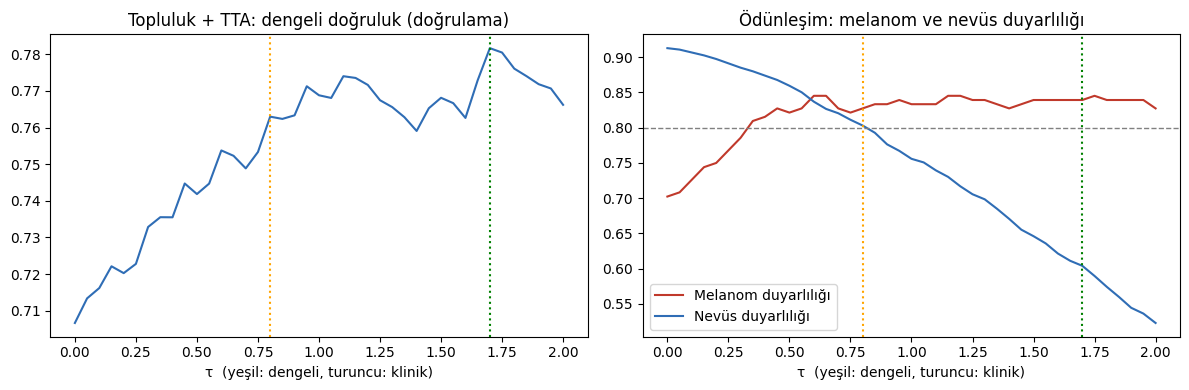

In [6]:
en_iyi = dog_tablo['dengeli_dogruluk'].max()
yakin = dog_tablo[dog_tablo['dengeli_dogruluk'] >= en_iyi - SECIM_FARKI].sort_values('nll')
SECILEN = yakin.index[0]
S = DONMUS[SECILEN]
print('Eşit sayılan adaylar (dengeli doğruluk farkı < 0,01):')
print(yakin[['dengeli_dogruluk', 'nll']].round(4).to_string())
print(f'\nSEÇİLEN SON CNN: {SECILEN}')
print(f'  T = {S["T"]:.3f} ({T_yorumu(S["T"])}) | τ klinik = {S["tau_klinik"]} | τ dengeli = {S["tau_dengeli"]}')

with open(f'{PROJE}/results/{ON}_secim_ve_donmus_ayarlar.json', 'w', encoding='utf-8') as f:
    json.dump({'secilen': SECILEN, 'kural': 'en yüksek doğrulama dengeli doğruluğu; 0,01 içinde ise en düşük doğrulama NLL',
               'nevus_alt_siniri': NEVUS_ALT_SINIR, 'adaylar': DONMUS,
               'dogrulama_tablosu': dog_tablo.reset_index().to_dict(orient='records')},
              f, ensure_ascii=False, indent=2, default=float)
print(f'Kaydedildi: results/{ON}_secim_ve_donmus_ayarlar.json')

z_dog = aday_logit(SECILEN, LOGIT_DOG)
egri = EGRILER[SECILEN]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(egri['tau'], egri['dengeli'], color='#2F6DB5'); ax[0].set_title(f'{SECILEN}: dengeli doğruluk (doğrulama)')
ax[1].plot(egri['tau'], egri['melanom_duy'], label='Melanom duyarlılığı', color='#C0392B')
ax[1].plot(egri['tau'], egri['nevus_duy'], label='Nevüs duyarlılığı', color='#2F6DB5')
ax[1].axhline(NEVUS_ALT_SINIR, color='gray', linestyle='--', linewidth=1)
ax[1].set_title('Ödünleşim: melanom ve nevüs duyarlılığı'); ax[1].legend()
for a in ax:
    a.axvline(S['tau_dengeli'], color='green', linestyle=':'); a.axvline(S['tau_klinik'], color='orange', linestyle=':')
    a.set_xlabel('τ  (yeşil: dengeli, turuncu: klinik)')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_tau_odunlesim.png', dpi=150); plt.show()

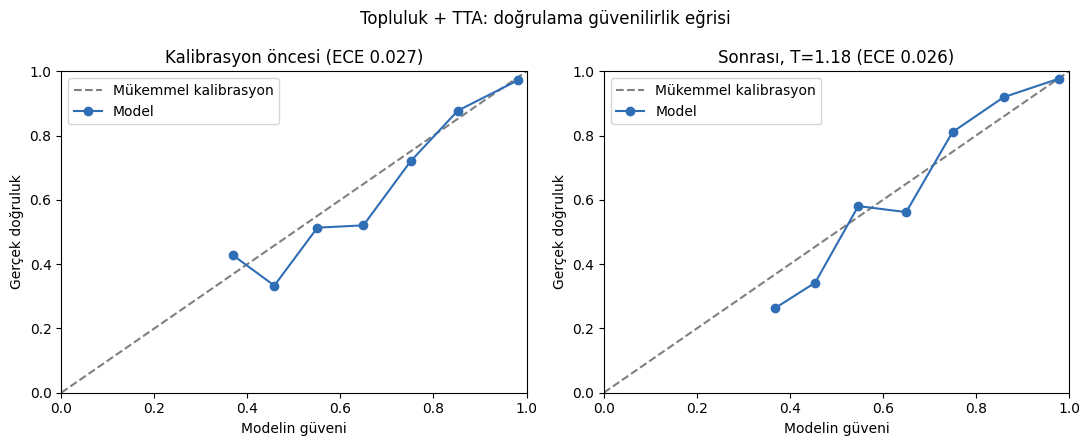

In [7]:
def guvenilirlik_egrisi(ax, olasilik, y, baslik, kutu=10):
    guven, dogru = olasilik.max(1), (olasilik.argmax(1) == y)
    s = np.linspace(0, 1, kutu + 1); orta, dogruluk = [], []
    for a, b in zip(s[:-1], s[1:]):
        m = (guven > a) & (guven <= b)
        if m.sum() >= 5:
            orta.append(guven[m].mean()); dogruluk.append(dogru[m].mean())
    ax.plot([0, 1], [0, 1], '--', color='gray', label='Mükemmel kalibrasyon')
    ax.plot(orta, dogruluk, 'o-', color='#2F6DB5', label='Model')
    ax.set_xlabel('Modelin güveni'); ax.set_ylabel('Gerçek doğruluk'); ax.set_title(baslik)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc='upper left')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
guvenilirlik_egrisi(ax[0], softmax(z_dog), y_dog, f'Kalibrasyon öncesi (ECE {ece(softmax(z_dog), y_dog):.3f})')
guvenilirlik_egrisi(ax[1], softmax(z_dog / S['T']), y_dog, f'Sonrası, T={S["T"]:.2f} (ECE {ece(softmax(z_dog / S["T"]), y_dog):.3f})')
plt.suptitle(f'{SECILEN}: doğrulama güvenilirlik eğrisi'); plt.tight_layout()
plt.savefig(f'{PROJE}/results/{ON}_kalibrasyon_dogrulama.png', dpi=150); plt.show()

## 5. Test kümesi: bütün adaylar
Ayarlar yukarıda donduruldu. Burada her aday, kendi dondurulmuş T ve τ değerleriyle test edilir. Bu tablo tezde **olduğu gibi** raporlanacak; seçilen aday testte en iyi çıkmasa bile değişmez.

In [8]:
LOGIT_TEST = {}
for m in TEMEL_MODELLER:
    t0 = time.time()
    LOGIT_TEST[m] = logit_hesapla(m, test)
    np.save(f'{PROJE}/models/{m}_test_logit_tek.npy', LOGIT_TEST[m]['tek'])
    np.save(f'{PROJE}/models/{m}_test_logit_tta.npy', LOGIT_TEST[m]['tta'])
    print(f'{m}: test logitleri {(time.time() - t0) / 60:.1f} dk')
np.save(f'{PROJE}/models/test_y.npy', y_test)

def test_olc(ad):
    d = DONMUS[ad]; z = aday_logit(ad, LOGIT_TEST); p = softmax(z / d['T'])
    th, tk, td = z.argmax(1), karar(z, d['tau_klinik']), karar(z, d['tau_dengeli'])
    return {'dengeli_dogruluk': balanced_accuracy_score(y_test, th), 'dogruluk': (th == y_test).mean(),
            'makro_auc': roc_auc_score(y_test, p, multi_class='ovr', average='macro', labels=range(len(SINIFLAR))),
            'melanom_duy': duyarlilik(y_test, th, MEL),
            'klinik_dengeli': balanced_accuracy_score(y_test, tk), 'klinik_dogruluk': (tk == y_test).mean(),
            'klinik_melanom_duy': duyarlilik(y_test, tk, MEL), 'klinik_nevus_duy': duyarlilik(y_test, tk, NV),
            'tau_d_dengeli': balanced_accuracy_score(y_test, td), 'tau_d_melanom_duy': duyarlilik(y_test, td, MEL),
            'tau_d_nevus_duy': duyarlilik(y_test, td, NV),
            'nll_kalibre': nll(z, y_test, d['T']), 'ece_kalibre': ece(p, y_test)}

test_tablo = pd.DataFrame({ad: test_olc(ad) for ad in ADAYLAR}).T
test_tablo.index = [ad + ('  <- SEÇİLEN' if ad == SECILEN else '') for ad in test_tablo.index]
print('TEST KÜMESİ: BÜTÜN ADAYLAR\n')
print('Ayarsız karar:')
print(test_tablo[['dengeli_dogruluk', 'dogruluk', 'makro_auc', 'melanom_duy']].round(3).to_string())
print('\nKlinik τ ile karar (sistemin ana kararı):')
print(test_tablo[['klinik_dengeli', 'klinik_dogruluk', 'klinik_melanom_duy', 'klinik_nevus_duy']].round(3).to_string())
print('\nDengeli τ ile karar (karşılaştırma):')
print(test_tablo[['tau_d_dengeli', 'tau_d_melanom_duy', 'tau_d_nevus_duy']].round(3).to_string())
print('\nKalibrasyon (dondurulmuş T ile):')
print(test_tablo[['nll_kalibre', 'ece_kalibre']].round(4).to_string())

cnn_b0_v3: test logitleri 1.2 dk
cnn_b3_v3: test logitleri 2.6 dk
cnn_b0_v4: test logitleri 1.2 dk
TEST KÜMESİ: BÜTÜN ADAYLAR

Ayarsız karar:
                            dengeli_dogruluk  dogruluk  makro_auc  melanom_duy
cnn_b0_v3                              0.647     0.804      0.960        0.571
cnn_b0_v3 + TTA                        0.643     0.809      0.962        0.595
cnn_b3_v3                              0.647     0.802      0.965        0.815
cnn_b3_v3 + TTA                        0.652     0.809      0.969        0.845
cnn_b0_v4                              0.622     0.809      0.960        0.452
cnn_b0_v4 + TTA                        0.632     0.805      0.961        0.446
Topluluk                               0.643     0.816      0.970        0.744
Topluluk + TTA  <- SEÇİLEN             0.653     0.821      0.972        0.756

Klinik τ ile karar (sistemin ana kararı):
                            klinik_dengeli  klinik_dogruluk  klinik_melanom_duy  klinik_nevus_duy
cnn_b0

## 6. Seçilen aday: ayrıntılı test analizi
- Sınıf bazında duyarlılık ve karışıklık matrisleri (ayarsız ve klinik τ).
- **Lezyon bazlı bootstrap** ile %95 güven aralıkları (1000 tekrar; bir lezyon seçilirse bütün görüntüleri gelir).
- Seçilen aday cnn_b0_v3'ten farklıysa, ikisinin farkı için **eşleştirilmiş** bootstrap aralığı: aralık 0'ı içeriyorsa fark istatistiksel olarak belirgin değildir.
- Patolojiyle doğrulanmış test görüntülerinde ayrıca sonuç.

Topluluk + TTA: sınıf bazında test sonuçları
                         ornek  duyarlilik_ayarsiz  duyarlilik_klinik  kesinlik_ayarsiz  kesinlik_klinik
Aktinik keratoz             51               0.471              0.510             0.750            0.553
Bazal hücreli karsinom      77               0.675              0.766             0.788            0.747
Benign keratoz             157               0.739              0.739             0.569            0.552
Dermatofibrom               22               0.500              0.636             0.688            0.350
Melanom                    168               0.756              0.869             0.557            0.410
Melanositik nevüs (ben)   1000               0.887              0.734             0.946            0.983
Vasküler lezyon             22               0.545              0.682             0.923            0.833


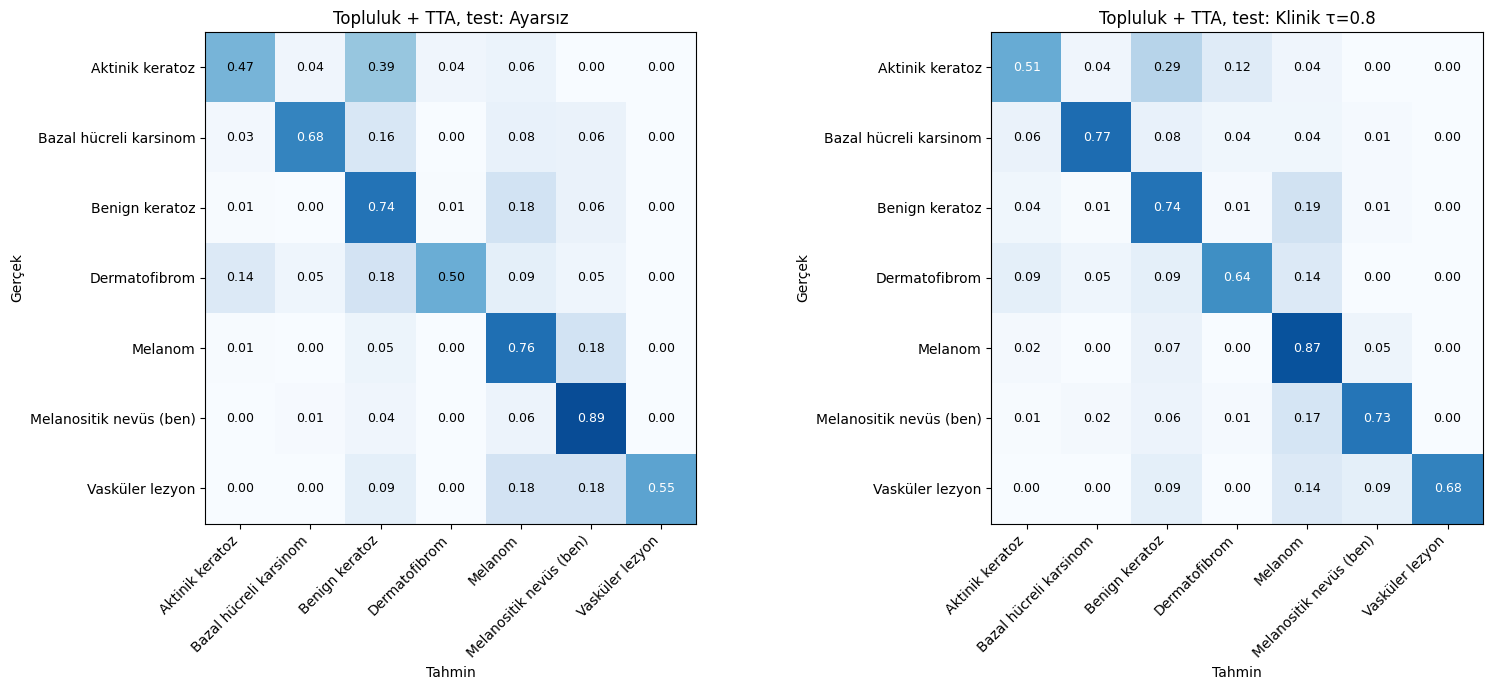

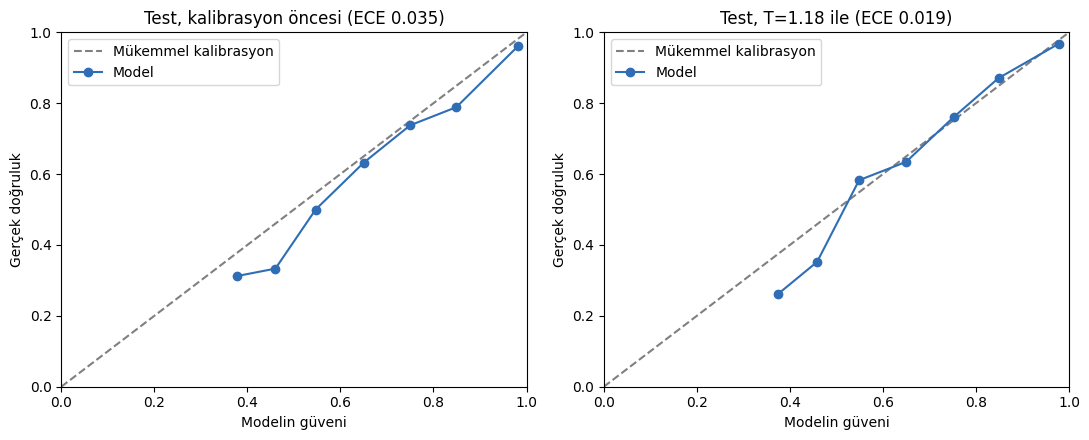

In [9]:
z_test = aday_logit(SECILEN, LOGIT_TEST)
p_test = softmax(z_test / S['T'])
tahmin_ham, tahmin_klinik = z_test.argmax(1), karar(z_test, S['tau_klinik'])

rh = classification_report(y_test, tahmin_ham, labels=range(len(SINIFLAR)), target_names=ETIKET, output_dict=True, zero_division=0)
rk = classification_report(y_test, tahmin_klinik, labels=range(len(SINIFLAR)), target_names=ETIKET, output_dict=True, zero_division=0)
print(f'{SECILEN}: sınıf bazında test sonuçları')
print(pd.DataFrame({'ornek': [int(rh[e]['support']) for e in ETIKET],
                    'duyarlilik_ayarsiz': [rh[e]['recall'] for e in ETIKET], 'duyarlilik_klinik': [rk[e]['recall'] for e in ETIKET],
                    'kesinlik_ayarsiz': [rh[e]['precision'] for e in ETIKET], 'kesinlik_klinik': [rk[e]['precision'] for e in ETIKET]},
                   index=ETIKET).round(3).to_string())

fig, eksen = plt.subplots(1, 2, figsize=(16, 7))
for ax, tah, baslik in [(eksen[0], tahmin_ham, 'Ayarsız'), (eksen[1], tahmin_klinik, f'Klinik τ={S["tau_klinik"]}')]:
    km = confusion_matrix(y_test, tah, labels=range(len(SINIFLAR)), normalize='true')
    ax.imshow(km, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(ETIKET)), ETIKET, rotation=45, ha='right'); ax.set_yticks(range(len(ETIKET)), ETIKET)
    for i in range(len(ETIKET)):
        for j in range(len(ETIKET)):
            ax.text(j, i, f'{km[i, j]:.2f}', ha='center', va='center', color='white' if km[i, j] > 0.5 else 'black', fontsize=9)
    ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek'); ax.set_title(f'{SECILEN}, test: {baslik}')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_test_karisiklik_matrisi.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
guvenilirlik_egrisi(ax[0], softmax(z_test), y_test, f'Test, kalibrasyon öncesi (ECE {ece(softmax(z_test), y_test):.3f})')
guvenilirlik_egrisi(ax[1], p_test, y_test, f'Test, T={S["T"]:.2f} ile (ECE {ece(p_test, y_test):.3f})')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_kalibrasyon_test.png', dpi=150); plt.show()

In [10]:
lezyon_gruplari = [np.array(ix) for ix in test.groupby('lesion_id').indices.values()]
def bootstrap_ornekleri(tekrar=1000):
    for _ in range(tekrar):
        secilen = rng.integers(0, len(lezyon_gruplari), len(lezyon_gruplari))
        yield np.concatenate([lezyon_gruplari[i] for i in secilen])
ORNEKLER = list(bootstrap_ornekleri())

def aralik(fonk):
    return np.nanpercentile([fonk(ix) for ix in ORNEKLER], [2.5, 97.5])

olcutler = {'dengeli_dogruluk': lambda t, ix: balanced_accuracy_score(y_test[ix], t[ix]),
            'dogruluk': lambda t, ix: (t[ix] == y_test[ix]).mean(),
            'melanom_duyarliligi': lambda t, ix: duyarlilik(y_test[ix], t[ix], MEL),
            'nevus_duyarliligi': lambda t, ix: duyarlilik(y_test[ix], t[ix], NV)}
tum = np.arange(len(test))
satirlar = []
for ad, tah in [('ayarsiz', tahmin_ham), ('klinik', tahmin_klinik)]:
    for olcut, f in olcutler.items():
        alt, ust = aralik(lambda ix, f=f, t=tah: f(t, ix))
        satirlar.append({'karar': ad, 'olcut': olcut, 'deger': f(tah, tum), 'alt_%95': alt, 'ust_%95': ust})
guven_araliklari = pd.DataFrame(satirlar)
print(f'{SECILEN}: %95 güven aralıkları (lezyon bazlı bootstrap)')
print(guven_araliklari.round(3).to_string(index=False))

fark_araligi = None
if SECILEN != 'cnn_b0_v3':
    z_ref = aday_logit('cnn_b0_v3', LOGIT_TEST)
    ref_ham, ref_klinik = z_ref.argmax(1), karar(z_ref, DONMUS['cnn_b0_v3']['tau_klinik'])
    fark_araligi = {}
    for ad, t1, t0 in [('ayarsiz', tahmin_ham, ref_ham), ('klinik', tahmin_klinik, ref_klinik)]:
        f = lambda ix, t1=t1, t0=t0: balanced_accuracy_score(y_test[ix], t1[ix]) - balanced_accuracy_score(y_test[ix], t0[ix])
        fark_araligi[ad] = [float(f(tum)), *map(float, aralik(f))]
    print(f'\nDengeli doğruluk farkı ({SECILEN} − cnn_b0_v3), eşleştirilmiş bootstrap:')
    for ad, (d, a, u) in fark_araligi.items():
        print(f'  {ad:8s}: {d:+.3f}  [%95: {a:+.3f}, {u:+.3f}]  -> {"belirgin" if a > 0 or u < 0 else "belirgin değil (aralık 0 içeriyor)"}')

histo = (test['dx_type'] == 'histo').values
print(f'\nPatolojiyle doğrulanmış test görüntüleri: {histo.sum()} / {len(test)}')
print(pd.DataFrame({ad: {'dengeli_dogruluk': balanced_accuracy_score(y_test[histo], t[histo]),
                         'dogruluk': (t[histo] == y_test[histo]).mean(),
                         'melanom_duyarliligi': duyarlilik(y_test[histo], t[histo], MEL)}
                    for ad, t in [('ayarsiz', tahmin_ham), ('klinik', tahmin_klinik)]}).round(3).to_string())

Topluluk + TTA: %95 güven aralıkları (lezyon bazlı bootstrap)
  karar               olcut  deger  alt_%95  ust_%95
ayarsiz    dengeli_dogruluk  0.653    0.590    0.728
ayarsiz            dogruluk  0.821    0.798    0.847
ayarsiz melanom_duyarliligi  0.756    0.667    0.838
ayarsiz   nevus_duyarliligi  0.887    0.863    0.912
 klinik    dengeli_dogruluk  0.705    0.642    0.764
 klinik            dogruluk  0.741    0.714    0.770
 klinik melanom_duyarliligi  0.869    0.803    0.928
 klinik   nevus_duyarliligi  0.734    0.701    0.770

Dengeli doğruluk farkı (Topluluk + TTA − cnn_b0_v3), eşleştirilmiş bootstrap:
  ayarsiz : +0.006  [%95: -0.032, +0.041]  -> belirgin değil (aralık 0 içeriyor)
  klinik  : +0.022  [%95: -0.027, +0.064]  -> belirgin değil (aralık 0 içeriyor)

Patolojiyle doğrulanmış test görüntüleri: 804 / 1497
                     ayarsiz  klinik
dengeli_dogruluk       0.575   0.633
dogruluk               0.703   0.603
melanom_duyarliligi    0.756   0.869


## 7. Uzmana yönlendirme ön analizi
Sistem emin olmadığı vakaları uzmana bırakırsa ne olur? Vakalar, kalibre olasılığın **sistemin kendi kararına** verdiği değere göre sıralanır; en az emin olunanlar uzmana gider.
- **Kapsama:** Sistemin kendisinin karar verdiği vakaların oranı.
- **Kaçırılan melanom:** Sistemin karar verip "melanom değil" dediği gerçek melanomlar (uzmana gidenler kaçırılmış sayılmaz).

Bu, konseyin karşılaştırılacağı **temel çizgidir**: konsey, aynı kapsamada bu çizgiden daha az melanom kaçırmalı ya da daha yüksek doğruluk vermelidir.

Test kümesinde toplam 168 melanom var.

--- Ayarsız ---
 kapsama  karar_verilen  uzmana_giden  dogruluk  dengeli_dogruluk  kacirilan_melanom  uzmana_giden_melanom
     1.0           1497             0     0.821             0.653                 41                     0
     0.9           1347           150     0.872             0.730                 29                    21
     0.8           1198           299     0.903             0.775                 16                    55
     0.7           1048           449     0.933             0.821                 11                    78
     0.6            898           599     0.960             0.850                  4                   109
     0.5            748           749     0.971             0.878                  2                   131

--- Klinik τ ---
 kapsama  karar_verilen  uzmana_giden  dogruluk  dengeli_dogruluk  kacirilan_melanom  uzmana_giden_melanom
     1.0           1497             0     0.741             0.705     

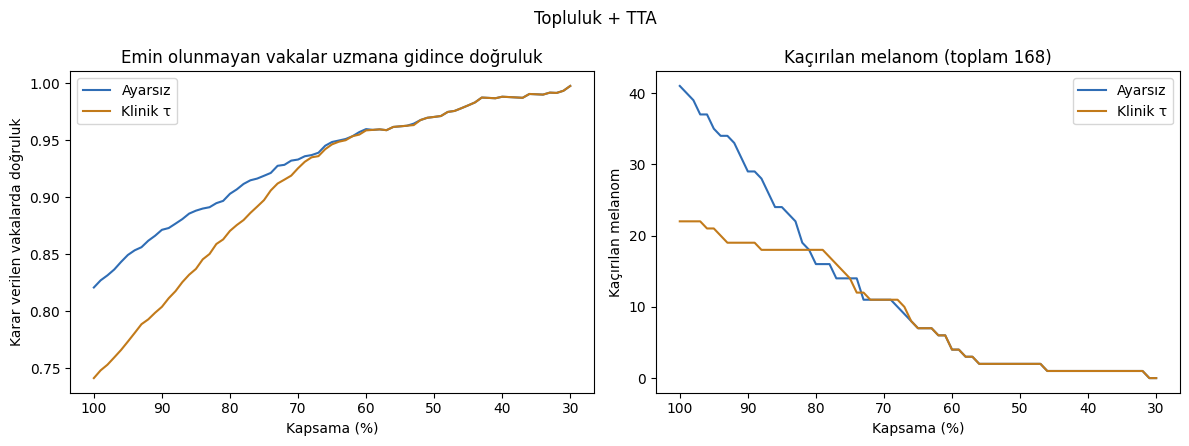

In [11]:
def secici_tahmin(tahmin, p, kapsama_listesi):
    guven = p[np.arange(len(tahmin)), tahmin]
    sira = np.argsort(-guven)
    satirlar = []
    for k in kapsama_listesi:
        n = int(round(k * len(tahmin))); kv = sira[:n]
        mel_kv = kv[y_test[kv] == MEL]
        satirlar.append({'kapsama': k, 'karar_verilen': n, 'uzmana_giden': len(tahmin) - n,
                         'dogruluk': (tahmin[kv] == y_test[kv]).mean(),
                         'dengeli_dogruluk': balanced_accuracy_score(y_test[kv], tahmin[kv]),
                         'kacirilan_melanom': int((tahmin[mel_kv] != MEL).sum()),
                         'uzmana_giden_melanom': int((y_test == MEL).sum() - len(mel_kv))})
    return pd.DataFrame(satirlar)

toplam_mel = int((y_test == MEL).sum())
print(f'Test kümesinde toplam {toplam_mel} melanom var.\n')
secici = {}
for ad, tah in [('Ayarsız', tahmin_ham), ('Klinik τ', tahmin_klinik)]:
    secici[ad] = secici_tahmin(tah, p_test, [1.0, 0.9, 0.8, 0.7, 0.6, 0.5])
    print(f'--- {ad} ---'); print(secici[ad].round(3).to_string(index=False)); print()

ince = np.round(np.arange(1.0, 0.29, -0.01), 2)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for ad, tah, renk in [('Ayarsız', tahmin_ham, '#2F6DB5'), ('Klinik τ', tahmin_klinik, '#C27A1A')]:
    d = secici_tahmin(tah, p_test, ince)
    ax[0].plot(d['kapsama'] * 100, d['dogruluk'], label=ad, color=renk)
    ax[1].plot(d['kapsama'] * 100, d['kacirilan_melanom'], label=ad, color=renk)
ax[0].set_xlabel('Kapsama (%)'); ax[0].set_ylabel('Karar verilen vakalarda doğruluk')
ax[0].set_title('Emin olunmayan vakalar uzmana gidince doğruluk'); ax[0].invert_xaxis(); ax[0].legend()
ax[1].set_xlabel('Kapsama (%)'); ax[1].set_ylabel('Kaçırılan melanom')
ax[1].set_title(f'Kaçırılan melanom (toplam {toplam_mel})'); ax[1].invert_xaxis(); ax[1].legend()
plt.suptitle(SECILEN); plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_uzmana_yonlendirme.png', dpi=150); plt.show()

## 8. Grad-CAM: model nereye bakıyor?
Isı haritası, kararı en çok etkileyen bölgeleri gösterir (kırmızı = en etkili). Seçilen aday bir topluluksa, iki modelin haritaları ayrı ayrı hesaplanıp normalize edilir ve ortalanır. Haritalar tek geçiş (TTA'sız) görüntü üzerinden hesaplanır.

**Kısa yol kontrolü:** Isı haritasının her kenardan %10'luk dış şeritte kalan payı. Lezyon genellikle ortada olduğu için, kenara yoğun bakan model cetvel, çerçeve veya kıl gibi ipuçlarından öğreniyor olabilir.

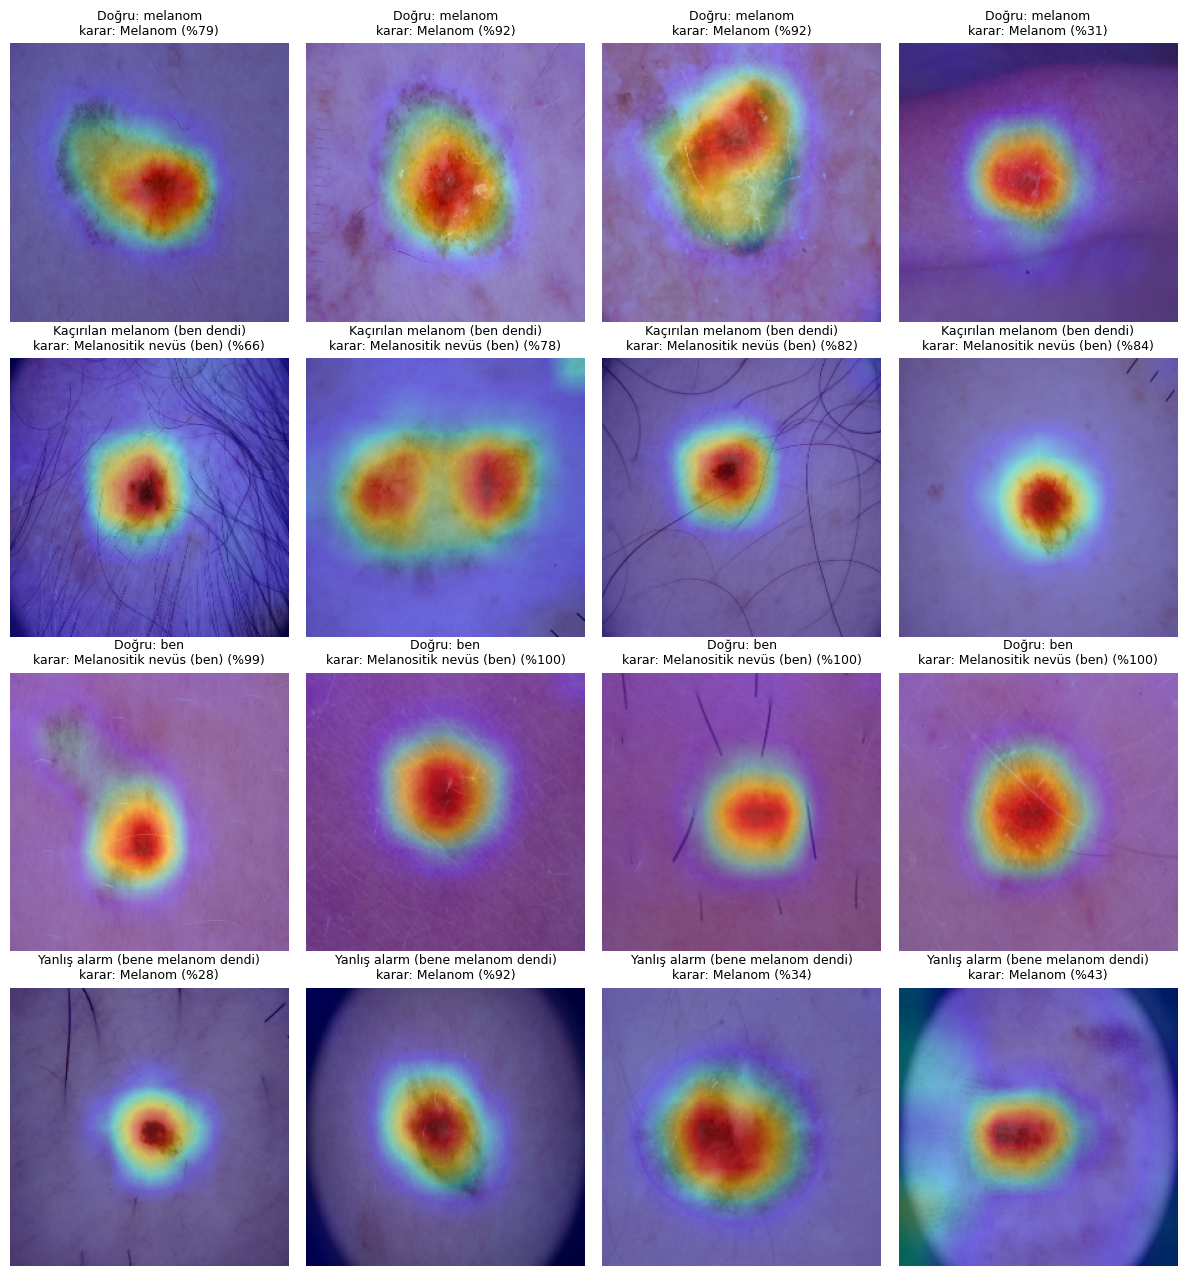

Gruplardaki görüntü sayıları: {'Doğru: melanom': 146, 'Kaçırılan melanom (ben dendi)': 8, 'Doğru: ben': 734, 'Yanlış alarm (bene melanom dendi)': 169}


In [12]:
GOSTER = 224
UYELER = S['uyeler']
CAM_MODELLERI = {m: keras.Model(MODELLER[m].inputs, [MODELLER[m].get_layer(BILGI[m]['cam_katmani']).output, MODELLER[m].output])
                 for m in UYELER}

def ham_goruntu(i):
    return tf.io.decode_jpeg(tf.io.read_file(test.loc[i, 'path']), channels=3)

def gradcam_tek(m, goruntu, sinif):
    x = onisle(goruntu, BILGI[m]['img'], BILGI[m]['onisleme'])[None]
    with tf.GradientTape() as tape:
        evrisim, logit = CAM_MODELLERI[m](x, training=False)
        skor = tf.cast(logit[:, sinif], tf.float32)
    grad = tf.cast(tape.gradient(skor, evrisim), tf.float32)
    evrisim = tf.cast(evrisim, tf.float32)
    cam = tf.nn.relu(tf.reduce_sum(evrisim * tf.reduce_mean(grad, axis=(1, 2))[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (GOSTER, GOSTER)).numpy()[..., 0]

def gradcam(i, sinif):
    g = ham_goruntu(i)
    return np.mean([gradcam_tek(m, g, sinif) for m in UYELER], axis=0)

def ciz(ax, i, sinif, baslik):
    g = tf.image.resize(ham_goruntu(i), (GOSTER, GOSTER)).numpy()
    ax.imshow(np.clip(g, 0, 255).astype('uint8')); ax.imshow(gradcam(i, sinif), cmap='jet', alpha=0.4)
    ax.set_title(baslik, fontsize=9); ax.axis('off')

gruplar = {'Doğru: melanom': np.where((y_test == MEL) & (tahmin_klinik == MEL))[0],
           'Kaçırılan melanom (ben dendi)': np.where((y_test == MEL) & (tahmin_klinik == NV))[0],
           'Doğru: ben': np.where((y_test == NV) & (tahmin_klinik == NV))[0],
           'Yanlış alarm (bene melanom dendi)': np.where((y_test == NV) & (tahmin_klinik == MEL))[0]}
fig, eksen = plt.subplots(len(gruplar), 4, figsize=(12, 3.2 * len(gruplar)))
for r, (ad, ix) in enumerate(gruplar.items()):
    secim = rng.choice(ix, size=min(4, len(ix)), replace=False) if len(ix) else []
    for c in range(4):
        ax = eksen[r, c]
        if c < len(secim):
            i = int(secim[c])
            ciz(ax, i, int(tahmin_klinik[i]), f'{ad}\nkarar: {SINIF_ADI[SINIFLAR[tahmin_klinik[i]]]} (%{100 * p_test[i, tahmin_klinik[i]]:.0f})')
        else:
            ax.axis('off')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_gradcam_ornekler.png', dpi=120); plt.show()
print('Gruplardaki görüntü sayıları:', {k: len(v) for k, v in gruplar.items()})

Süre: 48.1 dk
Kenar şeridi görüntü alanının %35'ini kaplıyor.
Isı haritasının kenardaki payı: ortanca %14; görüntülerin %1'inde kenar payı alan payından büyük.


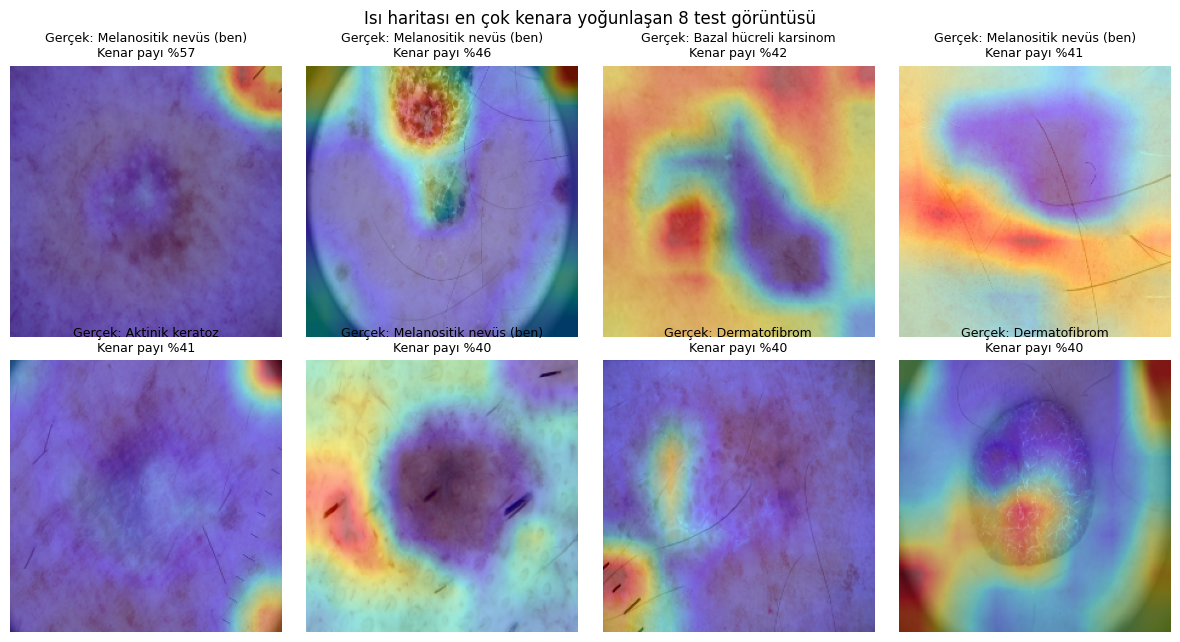

In [13]:
kenar = int(0.10 * GOSTER)
maske = np.ones((GOSTER, GOSTER), bool); maske[kenar:-kenar, kenar:-kenar] = False
kenar_alan_payi = maske.mean()

t0 = time.time()
kenar_payi = np.zeros(len(test))
for i in range(len(test)):
    cam = gradcam(i, int(tahmin_klinik[i]))
    kenar_payi[i] = cam[maske].sum() / (cam.sum() + 1e-8)
print(f'Süre: {(time.time() - t0) / 60:.1f} dk')
print(f'Kenar şeridi görüntü alanının %{100 * kenar_alan_payi:.0f}\'ini kaplıyor.')
print(f'Isı haritasının kenardaki payı: ortanca %{100 * np.median(kenar_payi):.0f}; '
      f'görüntülerin %{100 * (kenar_payi > kenar_alan_payi).mean():.0f}\'inde kenar payı alan payından büyük.')

en_kenar = np.argsort(-kenar_payi)[:8]
fig, eksen = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, i in zip(eksen.ravel(), en_kenar):
    ciz(ax, int(i), int(tahmin_klinik[i]), f'Gerçek: {SINIF_ADI[SINIFLAR[y_test[i]]]}\nKenar payı %{100 * kenar_payi[i]:.0f}')
plt.suptitle('Isı haritası en çok kenara yoğunlaşan 8 test görüntüsü'); plt.tight_layout()
plt.savefig(f'{PROJE}/results/{ON}_gradcam_kenar.png', dpi=120); plt.show()

## 9. Sonuçları kaydet ve CNN'i dondur
`results/03v2_son_cnn.json` sonraki bütün adımların okuyacağı tek dosyadır: hangi modeller, hangi ön işleme, TTA olup olmadığı, T ve τ. Seçilen adayın doğrulama ve test logitleri de `models/son_cnn_*.npy` olarak kaydedilir.

In [14]:
son_cnn = {'aday': SECILEN, 'uyeler': [{'model': m, 'dosya': f'models/{m}.keras', **BILGI[m]} for m in UYELER],
           'tta': S['tta'], 'T': S['T'], 'tau_klinik': S['tau_klinik'], 'tau_dengeli': S['tau_dengeli'],
           'ana_karar': 'klinik', 'log_oncel': LOG_ONCEL.tolist(), 'siniflar': SINIFLAR}
with open(f'{PROJE}/results/{ON}_son_cnn.json', 'w', encoding='utf-8') as f:
    json.dump(son_cnn, f, ensure_ascii=False, indent=2, default=float)
np.save(f'{PROJE}/models/son_cnn_dogrulama_logit.npy', z_dog)
np.save(f'{PROJE}/models/son_cnn_test_logit.npy', z_test)

cikti = {'secilen': SECILEN, 'donmus': DONMUS,
         'test_tum_adaylar': test_tablo.reset_index().rename(columns={'index': 'aday'}).to_dict(orient='records'),
         'guven_araliklari': guven_araliklari.to_dict(orient='records'), 'fark_cnn_b0_v3': fark_araligi,
         'uzmana_yonlendirme': {k: v.to_dict(orient='records') for k, v in secici.items()},
         'gradcam_kenar_payi_ortanca': float(np.median(kenar_payi)), 'gradcam_kenar_alan_payi': float(kenar_alan_payi)}
with open(f'{PROJE}/results/{ON}_test_sonuclari.json', 'w', encoding='utf-8') as f:
    json.dump(cikti, f, ensure_ascii=False, indent=2, default=float)
pd.DataFrame({'image_id': test['image_id'], 'lesion_id': test['lesion_id'], 'dx_type': test['dx_type'],
              'gercek': [SINIFLAR[i] for i in y_test],
              'tahmin_ayarsiz': [SINIFLAR[i] for i in tahmin_ham], 'tahmin_klinik': [SINIFLAR[i] for i in tahmin_klinik],
              'guven_klinik': p_test[np.arange(len(test)), tahmin_klinik], 'gradcam_kenar_payi': kenar_payi,
              **{f'p_{s}': p_test[:, i] for i, s in enumerate(SINIFLAR)}}).to_csv(f'{PROJE}/results/{ON}_test_tahminleri.csv', index=False)

print('Kaydedildi:')
for p in [f'results/{ON}_son_cnn.json', f'results/{ON}_secim_ve_donmus_ayarlar.json', f'results/{ON}_test_sonuclari.json',
          f'results/{ON}_test_tahminleri.csv', 'models/son_cnn_dogrulama_logit.npy', 'models/son_cnn_test_logit.npy',
          f'results/{ON}_tau_odunlesim.png', f'results/{ON}_kalibrasyon_dogrulama.png', f'results/{ON}_kalibrasyon_test.png',
          f'results/{ON}_test_karisiklik_matrisi.png', f'results/{ON}_uzmana_yonlendirme.png',
          f'results/{ON}_gradcam_ornekler.png', f'results/{ON}_gradcam_kenar.png']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')
print(f'\nSON CNN DONDURULDU: {SECILEN}')

Kaydedildi:
  results/03v2_son_cnn.json ✓
  results/03v2_secim_ve_donmus_ayarlar.json ✓
  results/03v2_test_sonuclari.json ✓
  results/03v2_test_tahminleri.csv ✓
  models/son_cnn_dogrulama_logit.npy ✓
  models/son_cnn_test_logit.npy ✓
  results/03v2_tau_odunlesim.png ✓
  results/03v2_kalibrasyon_dogrulama.png ✓
  results/03v2_kalibrasyon_test.png ✓
  results/03v2_test_karisiklik_matrisi.png ✓
  results/03v2_uzmana_yonlendirme.png ✓
  results/03v2_gradcam_ornekler.png ✓
  results/03v2_gradcam_kenar.png ✓

SON CNN DONDURULDU: Topluluk + TTA
